In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
import warnings
import json
import os

warnings.filterwarnings('ignore')
sns.set_style("whitegrid")

# 1. VERİ YÜKLEME
# ========================================================
# Yüklediğiniz dosya ismini kullanıyoruz
csv_path = 'processed_used_cars_model_ready_log.csv'

try:
    df = pd.read_csv(csv_path)
    print(f"Veri seti yüklendi: {csv_path}")
except FileNotFoundError:
    print(f"HATA: '{csv_path}' dosyası bulunamadı. Lütfen dosyayı yüklediğinizden emin olun.")
    # Kodun patlamaması için dummy işlem (Gerçekte dosya varsa burası çalışmaz)
    exit()

# Veriyi Hazırla
# Logaritmik 'price' hedef değişkenimiz. 'price_original' varsa atıyoruz.
X = df.drop(['price', 'price_original'], axis=1, errors='ignore')
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

Veri seti yüklendi: processed_used_cars_model_ready_log.csv


In [9]:
# 2. MODEL EĞİTİMİ (XGBoost)
# ========================================================
print("XGBoost modeli eğitiliyor...")
model = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
model.fit(X_train, y_train)

XGBoost modeli eğitiliyor...


,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [10]:
# 3. SHAP HATASI İÇİN CERRAHİ MÜDAHALE (JSON STRING FIX)
# ========================================================
print("Model JSON formatında temizleniyor...")

model_path = "temp_shap_model_final.json"
model.save_model(model_path)

# JSON Dosyasını Yükle
with open(model_path, 'r') as f:
    model_json = json.load(f)

# Hatalı parametreyi bul ve düzelt
# XGBoost bazen sayıyı liste olarak, bazen de liste görünümlü string olarak saklar.
fixed = False
try:
    if 'learner' in model_json and 'learner_model_param' in model_json['learner']:
        params = model_json['learner']['learner_model_param']
        
        if 'base_score' in params:
            val = params['base_score']
            print(f"Orijinal base_score değeri: {val} (Tip: {type(val)})")
            
            # DURUM 1: Değer gerçek bir liste ise ( ['0.5'] )
            if isinstance(val, list):
                params['base_score'] = val[0]
                fixed = True
                print(f"-> Liste formatı düzeltildi: {params['base_score']}")
            
            # DURUM 2: Değer string ise ama köşeli parantez içeriyorsa ( "[0.5]" ) <-- SİZİN HATANIZ BURADA
            elif isinstance(val, str) and val.strip().startswith('[') and val.strip().endswith(']'):
                # Köşeli parantezleri ve varsa tırnakları temizle
                clean_val = val.strip().strip('[]').strip("'").strip('"')
                params['base_score'] = clean_val
                fixed = True
                print(f"-> String-Liste formatı düzeltildi: {params['base_score']}")
            
            else:
                print("-> Format düzgün görünüyor, dokunulmadı.")

except Exception as e:
    print(f"JSON düzeltme uyarısı: {e}")

# Düzeltilmiş JSON'ı kaydet
if fixed:
    with open(model_path, 'w') as f:
        json.dump(model_json, f)
    print("JSON dosyası güncellendi.")

Model JSON formatında temizleniyor...
Orijinal base_score değeri: [1.0229673E1] (Tip: <class 'str'>)
-> String-Liste formatı düzeltildi: 1.0229673E1
JSON dosyası güncellendi.


In [11]:
# 4. TEMİZ MODELİ YÜKLE VE SHAP HESAPLA
# ========================================================
model_clean = XGBRegressor()
model_clean.load_model(model_path)
my_booster = model_clean.get_booster()
my_booster.feature_names = X_test.columns.tolist()

print("SHAP hesaplanıyor...")
explainer = shap.TreeExplainer(my_booster)
shap_values = explainer.shap_values(X_test)

print("SHAP hesaplaması BAŞARILI! Grafikler çiziliyor...")

SHAP hesaplanıyor...


ValueError: could not convert string to float: '[1.0229673E1]'

NameError: name 'shap_values' is not defined

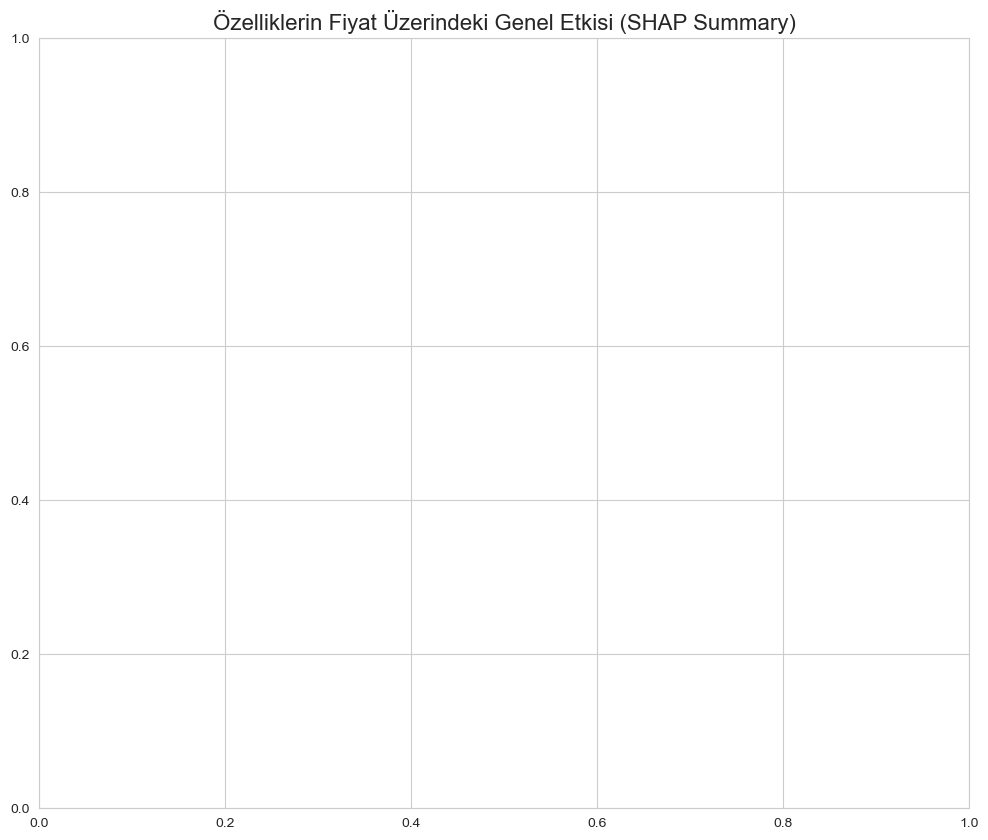

In [12]:
# ========================================================
# 5. GRAFİKLER (GLOBAL VE LOKAL)
# ========================================================

# Grafik 1: Summary Plot
plt.figure(figsize=(12, 10))
plt.title("Özelliklerin Fiyat Üzerindeki Genel Etkisi (SHAP Summary)", fontsize=16)
shap.summary_plot(shap_values, X_test, show=False)
plt.show()

# Grafik 2: Waterfall Plot (Rastgele Bir Araç)
random_idx = np.random.randint(0, len(X_test))
single_car_data = X_test.iloc[[random_idx]]
single_car_values = shap_values[random_idx]

# Fiyatları Geri Dönüştür (Log -> Dolar)
true_price_log = y_test.iloc[random_idx]
pred_price_log = model_clean.predict(single_car_data)[0]
true_price = np.expm1(true_price_log)
pred_price = np.expm1(pred_price_log)

print("\n" + "="*50)
print(f"ÖRNEK ARAÇ ANALİZİ (Index: {random_idx})")
print(f"Gerçek Fiyat: ${true_price:,.0f}")
print(f"Model Tahmini: ${pred_price:,.0f}")
print("="*50)

plt.figure(figsize=(10, 6))
shap_explanation = shap.Explanation(
    values=single_car_values,
    base_values=explainer.expected_value,
    data=single_car_data.values[0],
    feature_names=X_test.columns.tolist()
)
shap.plots.waterfall(shap_explanation, show=False)
plt.title(f"Fiyat Neden ${pred_price:,.0f}?", fontsize=14)
plt.show()

# Temizlik
if os.path.exists(model_path):
    os.remove(model_path)